In [1]:
# Install the libraries needed for Task 5

!pip install -q pandas numpy scikit-learn nltk matplotlib seaborn wordcloud gensim pyLDAvis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 23.6 MB/s eta 0:00:00


In [2]:
import pandas as pd
from sklearn.datasets import fetch_20newsgroups

# Load a sample news dataset as a fallback for learning topic modeling
news = fetch_20newsgroups(
    subset="all",
    remove=("headers", "footers", "quotes")
)

df = pd.DataFrame({
    "text": news.data,
    "category": [news.target_names[i] for i in news.target]
})

# Remove empty articles
df = df.dropna(subset=["text"])
df = df[df["text"].str.strip() != ""]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 articles:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (18331, 2)

Column names:
['text', 'category']

First 5 articles:


,text,category
0,\n\nI am sure some bashers of Pens fans are pr...,rec.sport.hockey
1,My brother is in the market for a high-perform...,comp.sys.ibm.pc.hardware
2,\n\n\n\n\tFinally you said what you dream abou...,talk.politics.mideast
3,\nThink!\n\nIt's the SCSI card doing the DMA t...,comp.sys.ibm.pc.hardware
4,1) I have an old Jasmine drive which I cann...,comp.sys.mac.hardware


In [3]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Download required NLTK resources
nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")

# Load English stopwords
stop_words = set(stopwords.words("english"))

# Function to clean and preprocess news text
def preprocess_text(text):
    text = text.lower()  # Convert to lowercase
    text = re.sub(r"[^a-z\s]", " ", text)  # Remove numbers and punctuation
    tokens = word_tokenize(text)  # Split text into words

    # Remove stopwords and very short words
    tokens = [
        word for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return tokens

# Apply preprocessing
df["tokens"] = df["text"].apply(preprocess_text)

# Remove articles that become empty
df = df[df["tokens"].map(len) > 0].copy()

print("Preprocessing completed!")
print("Dataset shape:", df.shape)
print("\nOriginal article:")
print(df["text"].iloc[0][:300])

print("\nProcessed tokens:")
print(df["tokens"].iloc[0][:30])

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Preprocessing completed!
Dataset shape: (18295, 3)

Original article:


I am sure some bashers of Pens fans are pretty confused about the lack
of any kind of posts about the recent Pens massacre of the Devils. Actually,
I am  bit puzzled too and a bit relieved. However, I am going to put an end
to non-PIttsburghers' relief with a bit of praise for the Pens. Man, they


Processed tokens:
['sure', 'bashers', 'pens', 'fans', 'pretty', 'confused', 'lack', 'kind', 'posts', 'recent', 'pens', 'massacre', 'devils', 'actually', 'bit', 'puzzled', 'bit', 'relieved', 'however', 'going', 'put', 'end', 'non', 'pittsburghers', 'relief', 'bit', 'praise', 'pens', 'man', 'killing']


In [4]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Convert token lists back into text
processed_texts = df["tokens"].apply(lambda tokens: " ".join(tokens))

# Convert text into a document-term matrix
vectorizer = CountVectorizer(
    max_df=0.90,
    min_df=5,
    max_features=10000
)

dtm = vectorizer.fit_transform(processed_texts)

print("Document-term matrix shape:", dtm.shape)

# Create the LDA model with 5 topics
lda_model = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    learning_method="batch",
    max_iter=10
)

# Train the model
lda_model.fit(dtm)

print("\nLDA model trained successfully!")
print("Number of topics:", lda_model.n_components)

Document-term matrix shape: (18295, 10000)

LDA model trained successfully!
Number of topics: 5


In [5]:
# Get all words from the vocabulary
words = vectorizer.get_feature_names_out()

# Display the top 10 words for each topic
number_of_top_words = 10

print("TOPIC MODELING RESULTS")
print("=" * 60)

for topic_idx, topic in enumerate(lda_model.components_):
    top_word_indices = topic.argsort()[-number_of_top_words:][::-1]
    top_words = [words[i] for i in top_word_indices]

    print(f"\nTopic {topic_idx + 1}:")
    print(", ".join(top_words))

TOPIC MODELING RESULTS

Topic 1:
people, would, one, government, think, right, like, also, many, even

Topic 2:
max, god, one, jesus, would, people, believe, bible, say, think

Topic 3:
edu, use, file, windows, system, also, com, one, get, software

Topic 4:
one, said, know, people, would, president, think, going, time, get

Topic 5:
would, one, like, get, good, think, time, know, could, much


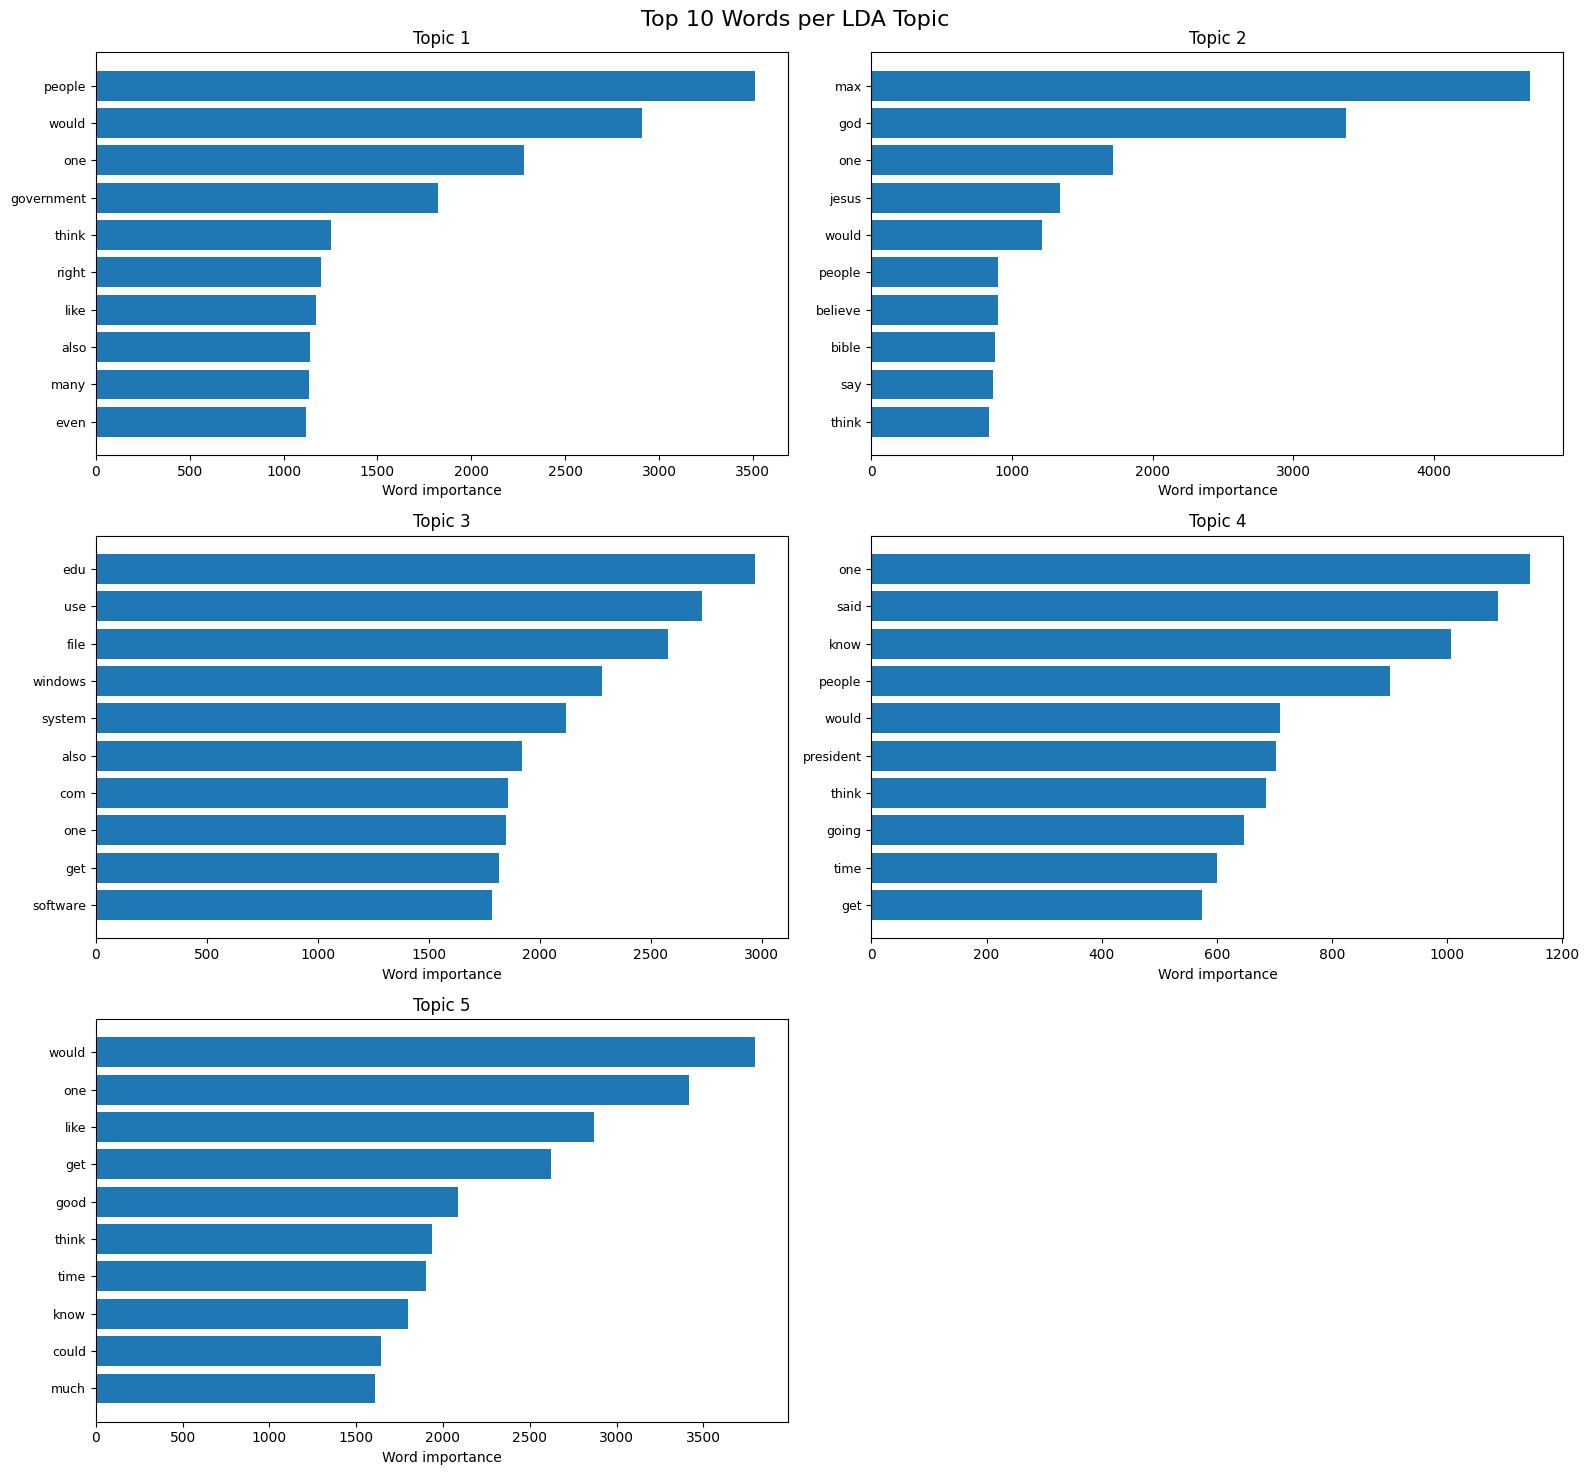

In [6]:
import matplotlib.pyplot as plt

words = vectorizer.get_feature_names_out()
number_of_top_words = 10

fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.flatten()

for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-number_of_top_words:]
    top_words = words[top_indices]
    top_weights = topic[top_indices]

    # Show the strongest word first at the top
    axes[topic_idx].barh(top_words, top_weights)
    axes[topic_idx].set_title(f"Topic {topic_idx + 1}")
    axes[topic_idx].set_xlabel("Word importance")
    axes[topic_idx].tick_params(axis="y", labelsize=9)

# Hide the unused sixth plot
axes[5].axis("off")

plt.suptitle("Top 10 Words per LDA Topic", fontsize=16)
plt.tight_layout()
plt.show()

In [7]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert articles into TF-IDF features for NMF
tfidf_vectorizer = TfidfVectorizer(
    max_df=0.90,
    min_df=5,
    max_features=10000
)

tfidf_matrix = tfidf_vectorizer.fit_transform(processed_texts)

# Train NMF with the same number of topics as LDA
nmf_model = NMF(
    n_components=5,
    random_state=42,
    max_iter=200
)

nmf_model.fit(tfidf_matrix)

print("NMF model trained successfully!")
print("Number of topics:", nmf_model.n_components)
print("TF-IDF matrix shape:", tfidf_matrix.shape)

NMF model trained successfully!
Number of topics: 5
TF-IDF matrix shape: (18295, 10000)


In [8]:
# Get the NMF vocabulary
nmf_words = tfidf_vectorizer.get_feature_names_out()

number_of_top_words = 10

print("NMF TOPIC MODELING RESULTS")
print("=" * 60)

for topic_idx, topic in enumerate(nmf_model.components_):
    top_indices = topic.argsort()[-number_of_top_words:][::-1]
    top_words = [nmf_words[i] for i in top_indices]

    print(f"\nTopic {topic_idx + 1}:")
    print(", ".join(top_words))

NMF TOPIC MODELING RESULTS

Topic 1:
would, one, people, think, like, get, time, well, good, even

Topic 2:
windows, dos, file, program, files, use, window, using, version, system

Topic 3:
god, jesus, bible, believe, christ, christian, faith, christians, people, sin

Topic 4:
drive, scsi, card, disk, ide, hard, drives, controller, bus, mac

Topic 5:
thanks, please, anyone, mail, know, advance, email, edu, would, looking


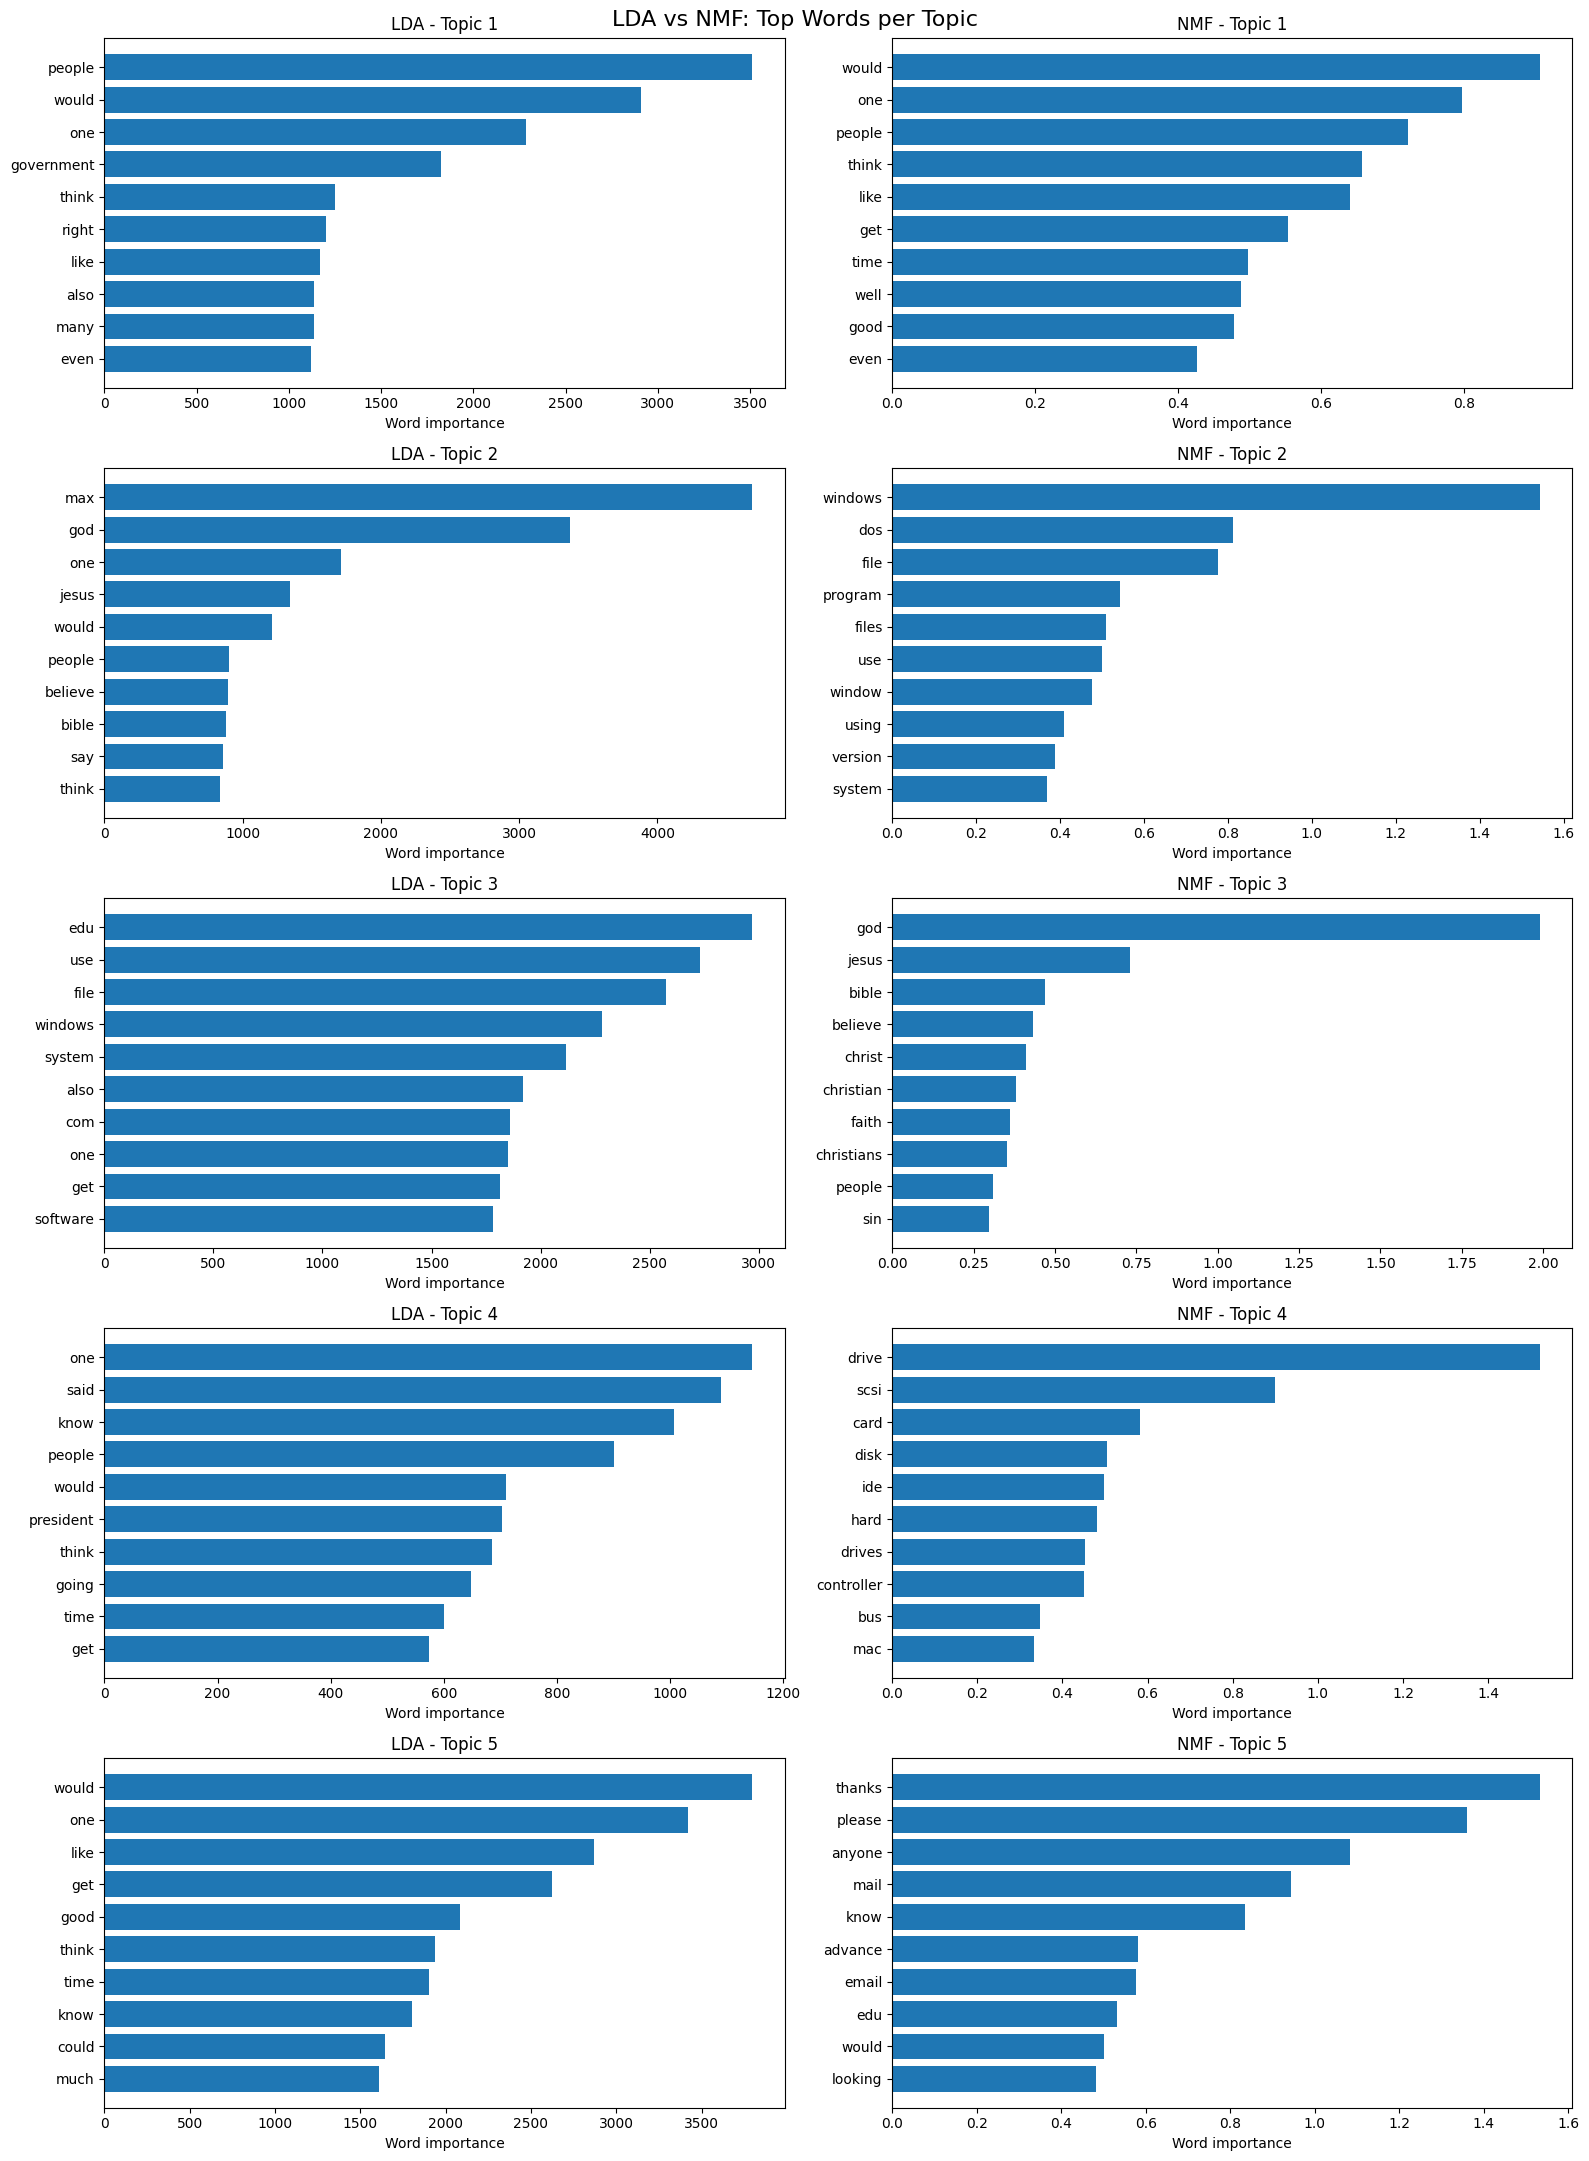

In [9]:
import matplotlib.pyplot as plt

lda_words = vectorizer.get_feature_names_out()
nmf_words = tfidf_vectorizer.get_feature_names_out()

fig, axes = plt.subplots(5, 2, figsize=(16, 22))

for i in range(5):
    # LDA: left column
    lda_top = lda_model.components_[i].argsort()[-10:]
    axes[i, 0].barh(
        lda_words[lda_top],
        lda_model.components_[i][lda_top]
    )
    axes[i, 0].set_title(f"LDA - Topic {i + 1}")
    axes[i, 0].set_xlabel("Word importance")

    # NMF: right column
    nmf_top = nmf_model.components_[i].argsort()[-10:]
    axes[i, 1].barh(
        nmf_words[nmf_top],
        nmf_model.components_[i][nmf_top]
    )
    axes[i, 1].set_title(f"NMF - Topic {i + 1}")
    axes[i, 1].set_xlabel("Word importance")

plt.suptitle("LDA vs NMF: Top Words per Topic", fontsize=16)
plt.tight_layout()
plt.show()

In [10]:
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel

# Build a dictionary from the preprocessed articles
dictionary = Dictionary(df["tokens"])

# Keep words that appear in at least 5 documents
dictionary.filter_extremes(no_below=5, no_above=0.90)

# Convert articles into Gensim bag-of-words format
corpus = [
    dictionary.doc2bow(tokens)
    for tokens in df["tokens"]
]

# Get top 10 words per LDA topic
lda_topics = []

for topic in lda_model.components_:
    top_indices = topic.argsort()[-10:][::-1]
    lda_topics.append([
        vectorizer.get_feature_names_out()[i]
        for i in top_indices
    ])

# Get top 10 words per NMF topic
nmf_topics = []

for topic in nmf_model.components_:
    top_indices = topic.argsort()[-10:][::-1]
    nmf_topics.append([
        tfidf_vectorizer.get_feature_names_out()[i]
        for i in top_indices
    ])

# Calculate coherence scores
lda_coherence = CoherenceModel(
    topics=lda_topics,
    texts=df["tokens"].tolist(),
    dictionary=dictionary,
    coherence="c_v"
).get_coherence()

nmf_coherence = CoherenceModel(
    topics=nmf_topics,
    texts=df["tokens"].tolist(),
    dictionary=dictionary,
    coherence="c_v"
).get_coherence()

print("TOPIC COHERENCE COMPARISON")
print("-" * 40)
print(f"LDA coherence: {lda_coherence:.4f}")
print(f"NMF coherence: {nmf_coherence:.4f}")

if lda_coherence > nmf_coherence:
    print("Higher coherence: LDA")
elif nmf_coherence > lda_coherence:
    print("Higher coherence: NMF")
else:
    print("Both models have equal coherence.")

TOPIC COHERENCE COMPARISON
----------------------------------------
LDA coherence: 0.5646
NMF coherence: 0.7045
Higher coherence: NMF


In [11]:
import pandas as pd

# Create a comparison table
results = pd.DataFrame({
    "Model": ["LDA", "NMF"],
    "Number_of_Topics": [5, 5],
    "Input_Features": ["Word Counts", "TF-IDF"],
    "Coherence_Score": [lda_coherence, nmf_coherence]
})

# Save the CSV file
results.to_csv("topic_modeling_comparison.csv", index=False)

print("Model comparison results:")
display(results)

print("\nCSV saved as topic_modeling_comparison.csv")

Model comparison results:


,Model,Number_of_Topics,Input_Features,Coherence_Score
0,LDA,5,Word Counts,0.564581
1,NMF,5,TF-IDF,0.704499



CSV saved as topic_modeling_comparison.csv
